# Arrhythmia classification from extracted ECG features

**Author: KOUADRI Soumia · Revised October 2026**

This project classifies heartbeat feature rows as N, VEB or Q. It completes the original exploratory project with reproducible experiments, subject-disjoint evaluation, model comparison and batch prediction. It is a research project, with no clinical validation.

The input is a derived feature table, **not raw ECG waveforms**. We preserve its three labels without asserting an unverified mapping to every original MIT-BIH annotation symbol. The original extraction code, precise feature units and distribution license were not supplied.

This notebook reads saved experiment results by default, so it can be executed without access to the private local CSV. Its optional training cell regenerates the results when the matching CSV is supplied. The repository contains the executed full-dataset results; no results below are placeholders.

In [1]:
from pathlib import Path
import json
import os
import sys
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))
REPORTS = ROOT / 'reports'
DATA = Path(os.environ.get('ARRHYTHMIA_DATA', str(ROOT / 'data' / 'mitbih_features.csv')))


## 1. Research questions and scope

1. How do linear SVM, Random Forest and a small tabular neural network compare on unseen subjects?
2. How optimistic is the original beat-random evaluation compared with held-out subjects?
3. Does class weighting improve validation macro-F1 over an unweighted forest?
4. Does training-fold quantile clipping help, and which features affect validation performance?
5. Does the proposed supervised normal/other → Q/VEB cascade help?
6. How does removing post-RR, which requires the next heartbeat, affect validation performance?

Waveform denoising and waveform CNNs require raw signals and a defined extraction process. Temporal sequence models require verified beat order or timestamps. Those original ideas are documented as future work rather than presented as completed experiments on this table. A multilayer perceptron is the appropriate small neural-network comparison for these tabular features.

## 2. Reproduce training (optional)

Set `ARRHYTHMIA_DATA` to your matching CSV and change `RUN_TRAINING` to `True`. This repeats the full experiment and writes a local model; it may take several minutes. Leave it `False` to inspect the published run.

In [2]:
RUN_TRAINING = False
if RUN_TRAINING:
    from arrhythmia.experiment import run
    import shutil
    destination = ROOT / 'artifacts' / 'notebook_run'
    run(DATA, destination, seed=42)
    REPORTS = destination
else:
    print('Using the committed full-dataset experiment results.')


Using the committed full-dataset experiment results.


## 3. Dataset audit and exploratory analysis

Counts and identical columns below are measured from the input CSV. A record ID is not always a unique person: records 201 and 202 share a subject, as documented by PhysioNet. Lead prefixes `0_` and `1_` refer to ECG channels, not successive beats. Strong correlation alone does not prove duplication. Identical columns are removed inside each training fold; no target-independent feature selection is fitted to the test set.

rows                                                            97107
columns                                                            34
feature_count                                                      32
records                                                            44
subject_groups                                                     43
missing_features                                                    0
duplicate_rows                                                      0
csv_sha256          0d5f9614bcfa5c09becf9f3cfdda1a6104093d01365a1f...
dtype: object

,beats,records_with_class
N,90083,44
VEB,7009,33
Q,15,5


,feature,identical_to
0,0_pre-RR,1_pre-RR
1,0_post-RR,1_post-RR
2,0_qPeak,0_qrs_morph0
3,1_qPeak,1_qrs_morph0


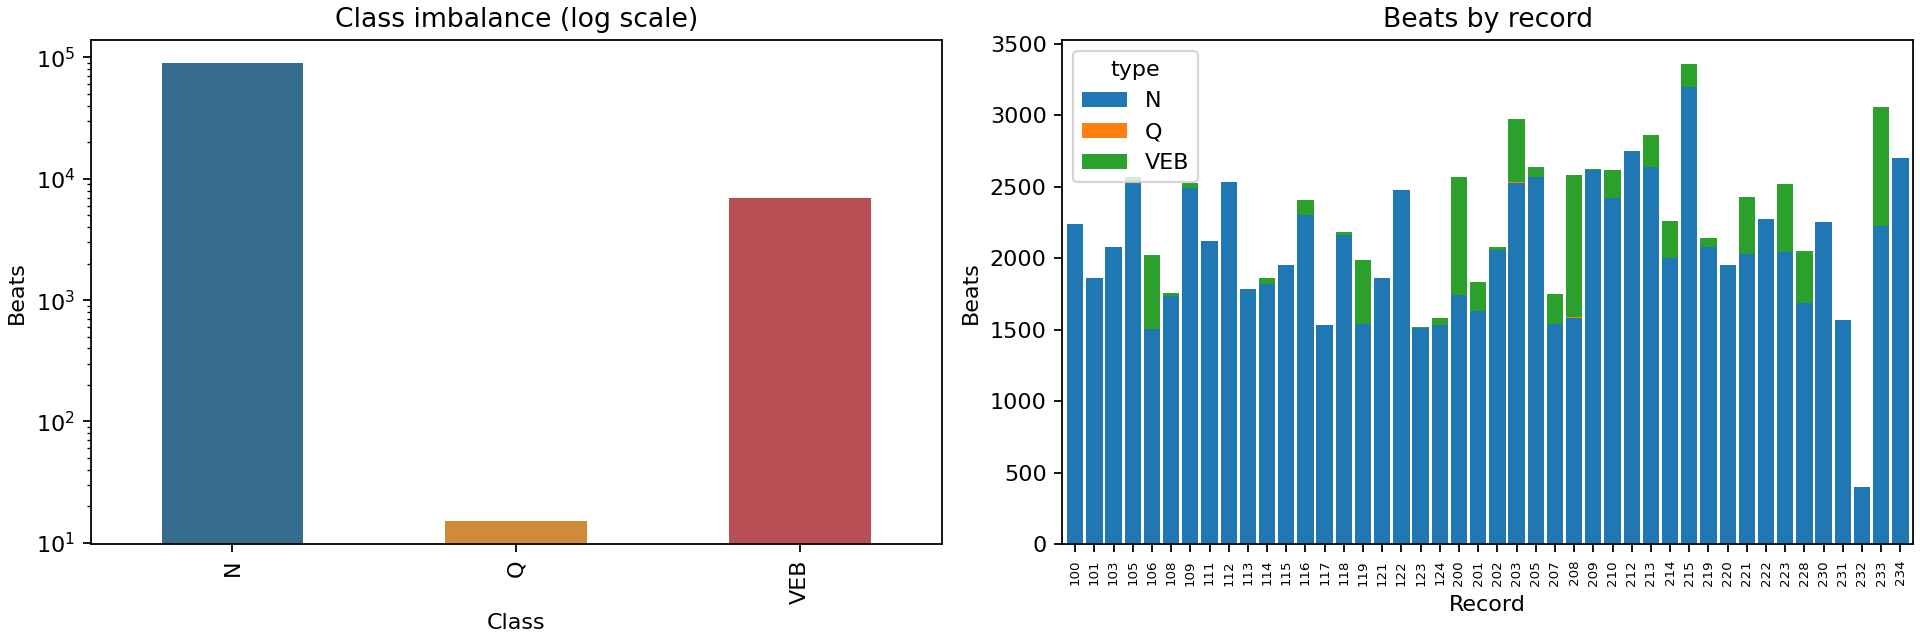

In [3]:
audit = json.loads((REPORTS / 'data_audit.json').read_text())
display(pd.Series({k: v for k, v in audit.items() if k not in ['identical_feature_pairs', 'class_counts', 'class_record_counts']}))
display(pd.DataFrame({'beats': audit['class_counts'], 'records_with_class': audit['class_record_counts']}))
display(pd.DataFrame(audit['identical_feature_pairs'], columns=['feature', 'identical_to']))
display(Image(filename=str(REPORTS / 'data_overview.png')))


## 4. Evaluation design

The first fold of a five-fold shuffled `StratifiedGroupKFold` (seed 42) is reserved as the test set, without searching for favorable splits. The remaining subjects form development data, with three grouped CV folds. All three classes must be present in each CV training fold. Some validation folds have no Q examples; fixed-label macro-F1 always includes all three labels, with zero for undefined F1. This penalizes missing Q performance consistently, but means fold scores are partly sensitive to rare-class support. Fold standard deviation is descriptive and is not a confidence interval.

Within every training fold: learn duplicate-feature removal and medians, optionally fit 0.5%/99.5% clipping bounds, then scale SVM/MLP inputs. Forests do not need scaling. The original SMOTE-before-CV step is replaced by a class-weighting experiment; weights avoid interpolating from the very few Q examples. The MLP is unweighted. Its early-stopping validation uses development-training rows only and is an optimization aid, not a held-out subject score.

Select one candidate by development mean macro-F1, then fit on all development subjects and evaluate that winner and the majority baseline on the held-out subjects once. The saved model remains fitted to development subjects only. No model-selection choice uses the test scores. This is a small predefined candidate comparison, not an exhaustive search.

The beat-random forest is a separate diagnostic with a different row split; it shares subjects between partitions and does not measure generalization to new people. Because its test composition differs, the gap cannot be attributed solely to splitting strategy.


In [4]:
metrics = json.loads((REPORTS / 'metrics.json').read_text())
manifest = pd.read_csv(REPORTS / 'split_manifest.csv')
dev = manifest[manifest.partition == 'development']
test = manifest[manifest.partition == 'test']
assert not set(dev.subject_group) & set(test.subject_group)
for fold in sorted(dev.cv_fold.unique()):
    assert not set(dev[dev.cv_fold == fold].subject_group) & set(dev[dev.cv_fold != fold].subject_group)
display(pd.DataFrame({'development': metrics['development_class_counts'], 'test': metrics['test_class_counts']}).fillna(0))
print('Held-out records:', metrics['test_records'])
print('No subject overlap in the outer split or inner CV folds.')


,development,test
N,71594,18489
VEB,5341,1668
Q,8,7


Held-out records: [105, 118, 122, 200, 214, 215, 228, 234]
No subject overlap in the outer split or inner CV folds.


## 5. Model comparison

The linear SVM replaces the original slow kernel-SVC sweep. The tabular MLP has hidden layers (32, 16), and up to 100 epochs with early stopping. Each forest has 120 trees with minimum leaf size 2. The two-stage model is supervised classification; it does not use a learned anomaly threshold or temporal context.

,model,cv_macro_f1,cv_macro_f1_std,cv_accuracy,fit_seconds
0,linear_svm_C0.1,0.529277,0.049185,0.924720,5.073111
1,linear_svm_C1,0.528391,0.049238,0.923457,5.297459
2,random_forest_clipped,0.523210,0.075138,0.941625,72.016388
3,random_forest_unweighted,0.518430,0.078821,0.937351,93.584349
4,two_stage_forest,0.514254,0.070487,0.937669,58.750889
5,random_forest_without_post_RR,0.510411,0.064116,0.937320,75.115844
6,random_forest_balanced,0.507531,0.049697,0.940722,62.013296
7,tabular_mlp,0.487568,0.054472,0.914019,16.544129
8,majority_baseline,0.321926,0.006731,0.934550,0.746797


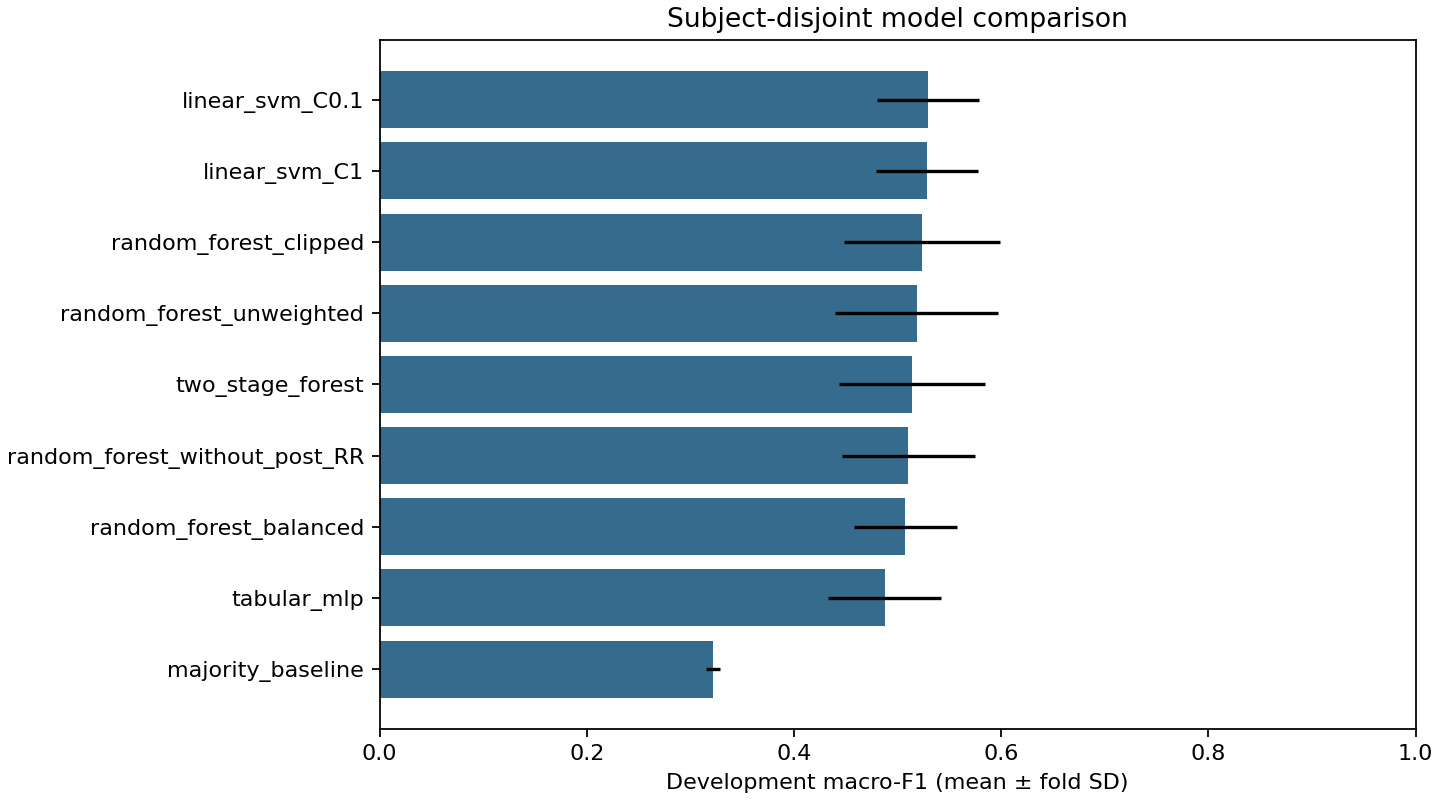

Selected by development CV: linear_svm_C0.1


""


In [5]:
comparison = pd.read_csv(REPORTS / 'model_comparison.csv')
display(comparison)
display(Image(filename=str(REPORTS / 'model_comparison.png')))
print('Selected by development CV:', metrics['selected_model'])
display(pd.DataFrame(metrics['convergence_warnings']))


## 6. Held-out results and errors

Accuracy is shown alongside macro-F1, per-class precision/recall/F1, and both count and row-normalized confusion matrices. The 15 Q examples overall are insufficient for reliable Q performance claims; the holdout contains only seven. A zero Q score is an observed failure, not evidence that Q can be ignored. No clinical thresholds or deployment-readiness claims are made.

,accuracy,macro_f1,macro_recall
evaluation,,,
Selected / held-out subjects,0.902995,0.513046,0.604405
Majority / held-out subjects,0.916931,0.318889,0.333333
Forest / beat-random diagnostic,0.996808,0.658878,0.655051


,precision,recall,f1-score,support
N,0.977002,0.916761,0.945923,18489.000000
Q,0.006452,0.142857,0.012346,7.000000
VEB,0.472556,0.753597,0.580869,1668.000000
accuracy,0.902995,0.902995,0.902995,0.902995
macro avg,0.485337,0.604405,0.513046,20164.000000
weighted avg,0.934936,0.902995,0.915401,20164.000000


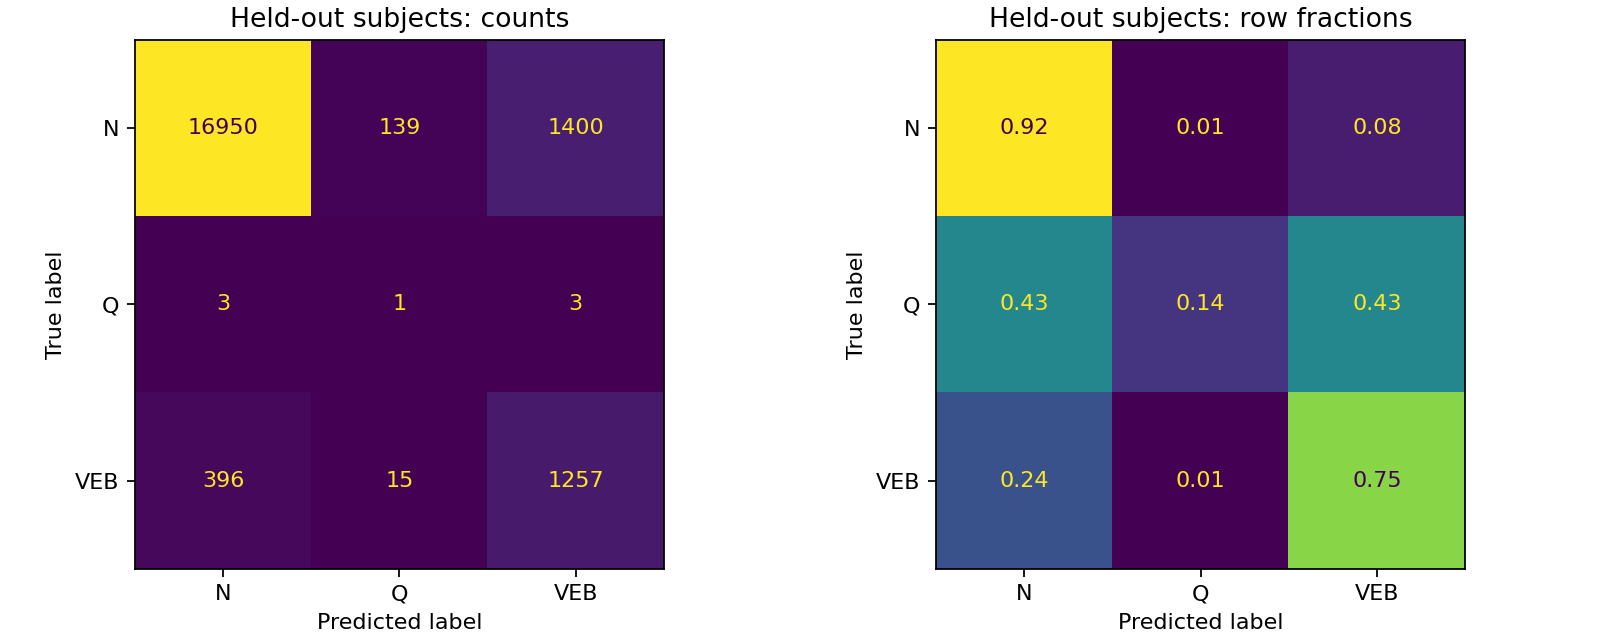

In [6]:
rows = []
for name, item in [('Selected / held-out subjects', metrics), ('Majority / held-out subjects', metrics['baseline']), ('Forest / beat-random diagnostic', metrics['beat_random_diagnostic'])]:
    rows.append({'evaluation': name, 'accuracy': item['accuracy'], 'macro_f1': item['macro_f1'], 'macro_recall': item['balanced_accuracy_fixed_labels']})
display(pd.DataFrame(rows).set_index('evaluation'))
display(pd.DataFrame(metrics['classification_report']).T)
display(Image(filename=str(REPORTS / 'confusion_matrix.png')))


## 7. Feature sensitivity

Permutation importance uses the selected model on development CV fold 0, with three repeats and at most 3,000 validation rows. Values measure predictive sensitivity, not physiological causality. Correlated features and fold-local duplicate removal can suppress individual importance; removed columns have no effect. The subset may not contain Q beats, so this cannot establish Q-specific explanations.

In [7]:
importance = pd.read_csv(REPORTS / 'feature_importance.csv')
display(importance.head(15))


,feature,mean_macro_f1_decrease,std
0,0_sPeak,0.121762,0.004287
1,0_tPeak,0.112156,0.003568
2,0_qrs_morph1,0.088598,0.002480
3,1_qrs_morph4,0.076417,0.001801
4,0_st_interval,0.073655,0.001964
5,0_pre-RR,0.067780,0.002321
6,1_qrs_morph2,0.067297,0.002536
7,0_rPeak,0.060617,0.002472
8,0_qrs_interval,0.048683,0.000987
9,0_qPeak,0.039322,0.001195


## 8. Answers, conclusions and limitations

In [8]:
scores = comparison.set_index('model').cv_macro_f1
winner = metrics['selected_model']
report = metrics['classification_report']
display(Markdown(f'''The highest development CV macro-F1 came from **{winner}** ({scores[winner]:.3f}). On held-out subjects it achieved accuracy **{metrics['accuracy']:.3f}** and macro-F1 **{metrics['macro_f1']:.3f}**. The majority baseline reached accuracy {metrics['baseline']['accuracy']:.3f}, which shows why accuracy alone is inadequate.

Class weighting changed forest CV macro-F1 from {scores['random_forest_unweighted']:.3f} to {scores['random_forest_balanced']:.3f}. Clipping produced {scores['random_forest_clipped']:.3f}, and removing post-RR produced {scores['random_forest_without_post_RR']:.3f}, compared with {scores['random_forest_balanced']:.3f} for the balanced forest. These are descriptive comparisons across the same three folds, without significance claims.

The tabular MLP achieved {scores['tabular_mlp']:.3f} and the two-stage approach achieved {scores['two_stage_forest']:.3f} in CV. The cascade can propagate gate errors and has very little Q data. It should not be assumed to solve rare-class detection.

The beat-random forest diagnostic reached macro-F1 {metrics['beat_random_diagnostic']['macro_f1']:.3f}, with {metrics['beat_random_diagnostic']['shared_subject_groups']} subjects shared between training and testing. Its different test population prevents treating the score difference as a controlled causal comparison.

On the held-out data, Q recall was {report['Q']['recall']:.3f} from {int(report['Q']['support'])} beats, and VEB recall was {report['VEB']['recall']:.3f}. **This evidence does not support reliable three-class clinical detection.** More independently recorded rare-class examples, a verified feature-extraction procedure, and external validation are needed.'''))


The highest development CV macro-F1 came from **linear_svm_C0.1** (0.529). On held-out subjects it achieved accuracy **0.903** and macro-F1 **0.513**. The majority baseline reached accuracy 0.917, which shows why accuracy alone is inadequate.

Class weighting changed forest CV macro-F1 from 0.518 to 0.508. Clipping produced 0.523, and removing post-RR produced 0.510, compared with 0.508 for the balanced forest. These are descriptive comparisons across the same three folds, without significance claims.

The tabular MLP achieved 0.488 and the two-stage approach achieved 0.514 in CV. The cascade can propagate gate errors and has very little Q data. It should not be assumed to solve rare-class detection.

The beat-random forest diagnostic reached macro-F1 0.659, with 43 subjects shared between training and testing. Its different test population prevents treating the score difference as a controlled causal comparison.

On the held-out data, Q recall was 0.143 from 7 beats, and VEB recall was 0.754. **This evidence does not support reliable three-class clinical detection.** More independently recorded rare-class examples, a verified feature-extraction procedure, and external validation are needed.

## 9. Prediction and responsible use

After training, run from the repository root:

```sh
arrhythmia predict --model artifacts/run/model.joblib --data data/new_features.csv --output artifacts/predictions.csv
```

Prediction requires the same 32 numeric extracted feature columns; `record` and `type` are optional metadata. Columns can be reordered. Missing values are filled using development-training medians. Missing/extra columns, nonnumeric values and infinity are rejected. Outputs are class labels, not calibrated diagnostic probabilities. Load only model artifacts you trust: joblib uses pickle.

Post-RR observes the next heartbeat, so the main feature set is offline and has look-ahead latency. Removing post-RR alone does not establish real-time readiness: other feature-extraction windows remain undocumented. No raw ECG upload or streaming detector is implemented.

No demographic fields are available, so fairness across demographic groups cannot be assessed. This historical cohort and very small rare-class sample limit generalization. Research software should not guide patient care without separate clinical validation.

## References and provenance

- [MIT-BIH Arrhythmia Database, PhysioNet](https://physionet.org/content/mitdb/1.0.0/), including the shared subject for records 201 and 202.
- [scikit-learn: common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html): train-only preprocessing and leakage prevention.
- [scikit-learn: grouped cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data).
- [scikit-learn: permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).

The historical source notebook is preserved under `archive/` with stale outputs removed. Its broader literature claims were not used as experimental evidence. AI assistance was used in both the original work (as disclosed there) and this revision. All reported experiment numbers are generated by the committed code on the supplied CSV, identified by the audit hash.
